# Interpolation to stations worldwide: GFS 2 m temperature

This example illustrates {func}`~grid_process.grid_interp.interp2poi` on a global grid with three methods:

- `nearest`: value of the nearest grid point;
- `linear`: bilinear interpolation on the regular latitude/longitude grid;
- `temp`: altitude-aware interpolation designed for temperature. It fits a local sounding on the `k`
  nearest grid points (with a distance penalizing altitude differences by `z_fact`) and evaluates it at
  the station altitude.

The 2 m temperature forecast of the NOAA Global Forecast System (GFS, regular 0.25° grid, about 28 km) is
interpolated to 33 stations around the world, and compared with their observations. They cover a wide
range of terrain:

- high mountains: Jungfraujoch, Säntis, Sonnblick, Mauna Loa and El Alto (La Paz);
- high cities and plateaus: Mexico City, Bogotá, Quito, Nairobi, Johannesburg, Denver,
  Salt Lake City, Ulaanbaatar and Tamanrasset;
- valleys: Innsbruck, Sion, Kathmandu and Santiago de Chile;
- coasts and islands, including three near the antimeridian: Nadi (Fiji), Fua'amotu (Tonga), Pago Pago,
  Honolulu, Dakar, Tokyo, Ushuaia, Christchurch and London;
- tropical lowland and desert: Manaus and Alice Springs;
- polar: Amundsen-Scott (South Pole), Alert, Utqiaġvik and Longyearbyen.

Since the grid and the stations are both in latitude/longitude and cover the globe, the nearest neighbor
searches of `nearest` and `temp` run in earth-centered earth-fixed coordinates (ECEF): distances are
measured in meters through the Earth, so they are correct everywhere, across the antimeridian and at the
poles.

*Data: NOAA Global Forecast System (GFS) and NOAA NCEI Global Historical Climatology Network hourly
(GHCNh), public domain. Coastlines: Natural Earth.*

In [1]:
import contextlib
import datetime as dt
import io
import os
import time
import timeit
from collections.abc import Callable
from concurrent.futures import ThreadPoolExecutor
from functools import partial
from typing import Any

# import pyproj before earthkit.data to avoid a crash at exit (earthkit-data#1202)
import pyproj  # noqa: F401  # pylint: disable=unused-import

# grid_process data model (read at import): the GHCNh station list columns give the POI labels and altitudes
os.environ["GRID_PROCESS__data_model__poi__coord_from"] = "GHCN_ID"
os.environ["GRID_PROCESS__data_model__poi__alt_from"] = '["ELEVATION"]'

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import earthkit.data as ekd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xarray as xr
from earthkit.data.utils import download_and_cache

import grid_process.grid_interp as gri
import grid_process.units_conv as uconv

# GHCNh station identifier: (short name, terrain)
STATIONS: dict[str, tuple[str, str]] = {
    "SZM00006730": ("Jungfraujoch", "high mountain"),
    "SZM00006680": ("Säntis", "high mountain"),
    "AUM00011343": ("Sonnblick", "high mountain"),
    "USW00021514": ("Mauna Loa", "high mountain"),
    "BLI0000SLLP": ("El Alto", "high mountain"),
    "MXI0000MMMX": ("Mexico City", "high city"),
    "COI0000SKBO": ("Bogotá", "high city"),
    "ECI0000SEQM": ("Quito", "high city"),
    "KEI0000HKJK": ("Nairobi", "high city"),
    "SFI0000FAOR": ("Johannesburg", "high city"),
    "USW00003017": ("Denver", "high city"),
    "USW00024127": ("Salt Lake City", "high city"),
    "MGI0000ZMUB": ("Ulaanbaatar", "high city"),
    "AGI0000DAAT": ("Tamanrasset", "high city"),
    "AUI0000LOWI": ("Innsbruck", "valley"),
    "SZI0000LSGS": ("Sion", "valley"),
    "NPI0000VNKT": ("Kathmandu", "valley"),
    "CIN00330021": ("Santiago", "valley"),
    "FJI0000NFFN": ("Nadi", "coast/island"),
    "TNI0000NFTF": ("Fua'amotu", "coast/island"),
    "AQW00061705": ("Pago Pago", "coast/island"),
    "USW00022521": ("Honolulu", "coast/island"),
    "SGI0000GOOY": ("Dakar", "coast/island"),
    "JAI0000RJTT": ("Tokyo", "coast/island"),
    "ARI0000SAWH": ("Ushuaia", "coast/island"),
    "NZI0000NZCH": ("Christchurch", "coast/island"),
    "UKI0000EGLL": ("London", "coast/island"),
    "BRM00081730": ("Manaus", "lowland/desert"),
    "ASI0000YBAS": ("Alice Springs", "lowland/desert"),
    "AYU089009-1": ("South Pole", "polar"),
    "CAMU0019939": ("Alert", "polar"),
    "USW00027502": ("Utqiaġvik", "polar"),
    "SVI0000ENSB": ("Longyearbyen", "polar"),
}
METHODS: dict[str, dict[str, Any]] = {
    "nearest": {"method": "nearest", "try_reg": False},
    "linear": {"method": "linear"},
    "temp": {"method": "temp", "z_fact": 15, "k": 50, "weight_power": 0.75},
}
RUN_DAYS_AGO = 3  # GHCNh observations are published with a delay of about two days
LEAD_H = 12  # lead time [h]

## Source data

GFS forecasts are archived on the NOAA Open Data Dissemination program (AWS). We take the 00 UTC run of
three days ago at the lead time of 12 hours, so that the observations of the valid time are already
published. A GFS file holds all variables (about 500 MB): with its index file, only the 2 m temperature
and the model orography (`HGT` at the surface, needed by `temp`) are downloaded, as byte ranges. The grid
keeps the GFS longitudes from 0° to 360°, while the stations use -180° to 180°: `grid_process` handles
both conventions.

In [2]:
run = dt.datetime.combine(dt.date.today() - dt.timedelta(days=RUN_DAYS_AGO), dt.time(0))
valid_time = pd.Timestamp(run + dt.timedelta(hours=LEAD_H))
url = (
    f"https://noaa-gfs-bdp-pds.s3.amazonaws.com/gfs.{run:%Y%m%d}/{run:%H}/atmos/gfs.t{run:%H}z.pgrb2.0p25.f{LEAD_H:03d}"
)
print(f"GFS run {run:%Y-%m-%d %H} UTC, lead time {LEAD_H} h, valid {valid_time:%Y-%m-%d %H:%M} UTC")

# index lines "number:offset:date:variable:level:forecast:": byte ranges of the needed fields
index = [line.split(":") for line in requests.get(f"{url}.idx", timeout=60).text.splitlines()]
offsets = [int(line[1]) for line in index] + [None]
parts = [
    (offsets[i], offsets[i + 1] - offsets[i])
    for i, line in enumerate(index)
    if (line[3], line[4]) in (("TMP", "2 m above ground"), ("HGT", "surface"))
]

# hide the download progress bars that earthkit always shows on stderr
with contextlib.redirect_stderr(io.StringIO()):
    gfs = ekd.from_source("url", url, parts=parts).to_xarray()
ds = uconv.ds_to(gfs[["2t"]].astype("float32"), {"2t": "degC"})
ds = ds.assign_coords(surface_altitude=gfs["orog"].astype("float32").assign_attrs(units="m"))
ds

GFS run 2026-11-06 00 UTC, lead time 12 h, valid 2026-11-06 12:00 UTC


<xarray.Dataset> Size: 8MB
Dimensions:           (latitude: 721, longitude: 1440)
Coordinates:
  * latitude          (latitude) float64 6kB 90.0 89.75 89.5 ... -89.75 -90.0
  * longitude         (longitude) float64 12kB 0.0 0.25 0.5 ... 359.5 359.8
    surface_altitude  (latitude, longitude) float32 4MB 0.05937 ... 2.775e+03
Data variables:
    2t                (latitude, longitude) float32 4MB -17.29 -17.29 ... -39.52
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## Stations and observations

The stations and their observations come from the Global Historical Climatology Network hourly (GHCNh)
of NOAA NCEI, which collects SYNOP and METAR reports worldwide. Its station list provides the coordinates
and the altitude used by `temp`. Instead of renaming its columns, the environment variables set in the
setup cell adapt the `grid_process` data model: the `GHCN_ID` column becomes the `poi` coordinate of the
output and `ELEVATION` gives the altitude.

The observation is the 2 m temperature report closest to the valid time, within one hour: some stations
do not report every hour (e.g. the South Pole only at the main synoptic hours, while GHCNh lacks some of
these hours for Jungfraujoch and Säntis). Values flagged by the quality control of GHCNh (suspect or
erroneous) are discarded, and stations without a valid report are left out.

In [3]:
GHCNH_URL = "https://www.ncei.noaa.gov/oa/global-historical-climatology-network/hourly"
FAILED_QC = ("2", "3", "6", "7")  # legacy codes: suspect or erroneous; lower case letters: failed checks

stations = pd.read_csv(f"{GHCNH_URL}/doc/ghcnh-station-list.csv").set_index("GHCN_ID", drop=False)
stations = stations.loc[list(STATIONS)]
stations["name"] = [name for name, _ in STATIONS.values()]
stations["terrain"] = [terrain for _, terrain in STATIONS.values()]


def observation(ghcn_id: str) -> float:
    """Valid 2 m temperature report closest to the valid time (within one hour), NaN if there is none."""
    url = f"{GHCNH_URL}/access/by-year/{valid_time.year}/psv/GHCNh_{ghcn_id}_{valid_time.year}.psv"
    if not requests.head(url, timeout=60, allow_redirects=True).ok:  # no data this year
        return np.nan
    # the yearly files are downloaded once into the earthkit cache (hide the progress bar on stderr)
    with contextlib.redirect_stderr(io.StringIO()):
        path = download_and_cache(url)
    columns = ["DATE", "temperature", "temperature_Quality_Code"]
    df = pd.read_csv(path, sep="|", usecols=columns, dtype={"temperature_Quality_Code": str})
    code = df["temperature_Quality_Code"].fillna("")
    df = df[df["temperature"].notna() & ~code.isin(FAILED_QC) & ~code.str.islower()]
    offset = (pd.to_datetime(df["DATE"]) - valid_time).abs()
    df = df[offset <= pd.Timedelta(hours=1)]
    return np.nan if df.empty else float(df.loc[offset[df.index].idxmin(), "temperature"])


with ThreadPoolExecutor(8) as executor:
    stations["observation"] = list(executor.map(observation, stations.index))

missing = stations[stations["observation"].isna()]
print(f"No valid observation at {valid_time:%Y-%m-%d %H:%M} UTC for: {', '.join(missing['name']) or 'none'}")
stations = stations.dropna(subset=["observation"])
pois = gpd.GeoDataFrame(
    stations, geometry=gpd.points_from_xy(stations["LONGITUDE"], stations["LATITUDE"]), crs="EPSG:4326"
)
pois[["name", "terrain", "LATITUDE", "LONGITUDE", "ELEVATION", "observation"]]

No valid observation at 2026-11-06 12:00 UTC for: none


,name,terrain,LATITUDE,LONGITUDE,ELEVATION,observation
GHCN_ID,,,,,,
SZM00006730,Jungfraujoch,high mountain,46.5500,7.9833,3576.0,-6.50
SZM00006680,Säntis,high mountain,47.2500,9.3500,2500.0,-0.20
AUM00011343,Sonnblick,high mountain,47.0500,12.9500,3113.8,-2.80
USW00021514,Mauna Loa,high mountain,19.5353,-155.5761,3407.4,7.10
BLI0000SLLP,El Alto,high mountain,-16.5133,-68.1923,4061.5,10.00
MXI0000MMMX,Mexico City,high city,19.4363,-99.0721,2229.9,10.00
COI0000SKBO,Bogotá,high city,4.7016,-74.1469,2548.4,12.00
ECI0000SEQM,Quito,high city,-0.1167,-78.3667,2400.0,13.00
KEI0000HKJK,Nairobi,high city,-1.3192,36.9278,1623.7,24.00


## Interpolation

Each method is called once, and the duration of this first call is kept for the benchmark below.

The grid and the stations are both in latitude/longitude, and the stations are far beyond the range of
the Swiss coordinates LV95 (`lv95_max_offset`): `nearest` and `temp` search their neighbors in ECEF
coordinates. `linear` cannot triangulate points on a sphere in ECEF and raises an error with the generic
path (`try_reg=False`), as shown below. On a regular grid like GFS, it uses the regular grid
interpolation instead (`try_reg=True`, the default), bilinear in latitude and longitude.

In [4]:
results: dict[str, xr.Dataset] = {}
first_call: dict[str, float] = {}
for label, kwargs in METHODS.items():
    t0 = time.perf_counter()
    results[label] = gri.interp2poi(ds, pois, **kwargs)
    first_call[label] = time.perf_counter() - t0
    pois[label] = results[label]["2t"].to_series()

try:
    gri.interp2poi(ds, pois, "linear", try_reg=False)
except ValueError as error:
    print(f"linear with try_reg=False: {error}")

# model altitude at the nearest grid point, to compare with the station altitude
alt = ds["surface_altitude"].reset_coords(drop=True).to_dataset(name="alt")
pois["model altitude"] = gri.interp2poi(alt, pois, "nearest", try_reg=False)["alt"].to_series()
results["temp"]

linear with try_reg=False: Method 'linear' is not supported for geographic grids beyond 700 km of the Swiss LV95 central northing, which are interpolated in earth-centered earth-fixed (ECEF) coordinates: a Delaunay triangulation of points close to the Earth's surface is degenerate in ECEF. Use e.g. method='idw' instead, or try_reg=True for a regular grid with 1D coordinates (or adjust GRID_PROCESS__lv95_max_offset).


<xarray.Dataset> Size: 2kB
Dimensions:  (poi: 33)
Coordinates:
  * poi      (poi) <U11 1kB 'SZM00006730' 'SZM00006680' ... 'SVI0000ENSB'
Data variables:
    2t       (poi) float32 132B -7.609 2.084 -1.002 ... -20.62 -4.915 -5.307
Attributes:
    institution:  ECMWF

## Visual comparison

The maps show the observations and the difference between each method and the observation, on a common
colour scale centred on zero. The table below lists the values per station, and the last figure relates
the errors to the difference between the model altitude (at the nearest grid point) and the station
altitude.

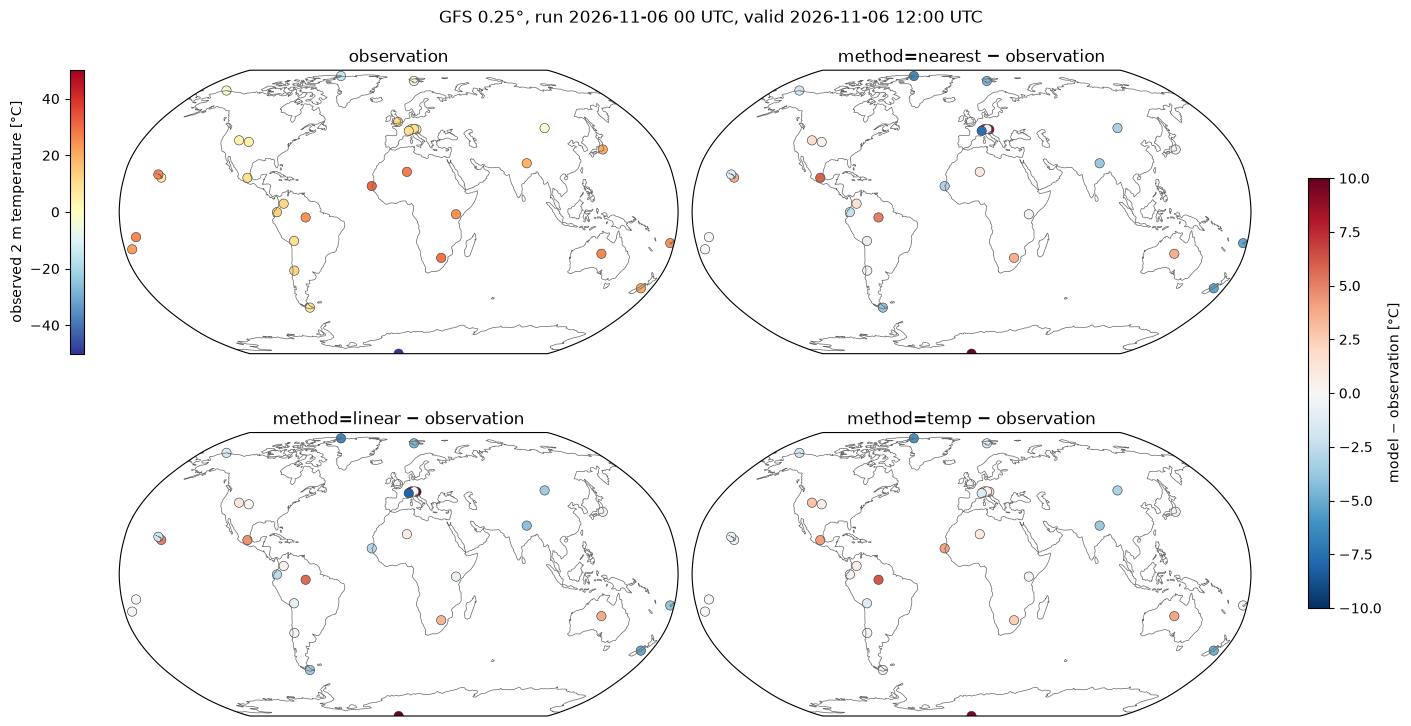

In [5]:
diff = pois[list(METHODS)].sub(pois["observation"], axis=0)
diff_lim = np.ceil(np.nanmax(np.abs(diff.to_numpy())))
obs_lim = np.ceil(np.nanmax(np.abs(pois["observation"])))
panels = [("observation", pois["observation"], "RdYlBu_r", -obs_lim, obs_lim)]
panels += [(f"method={label} − observation", diff[label], "RdBu_r", -diff_lim, diff_lim) for label in METHODS]

fig, axes = plt.subplots(
    2, 2, figsize=(14, 7.5), layout="constrained", subplot_kw={"projection": ccrs.Robinson(central_longitude=0)}
)
for ax, (title, values, cmap, vmin, vmax) in zip(axes.flat, panels):
    ax.set_global()
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor="0.4")
    scatter = ax.scatter(
        pois["LONGITUDE"],
        pois["LATITUDE"],
        c=values,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        s=45,
        edgecolor="0.2",
        linewidth=0.4,
        transform=ccrs.PlateCarree(),
    )
    ax.set_title(title)
    if title == "observation":
        fig.colorbar(scatter, ax=ax, location="left", shrink=0.8, label="observed 2 m temperature [°C]")
fig.colorbar(scatter, ax=axes, shrink=0.6, label="model − observation [°C]")
fig.suptitle(f"GFS 0.25°, run {run:%Y-%m-%d %H} UTC, valid {valid_time:%Y-%m-%d %H:%M} UTC")
plt.show()

In [6]:
table = pois[["name", "terrain", "ELEVATION", "model altitude", "observation", *METHODS]].rename(
    columns={
        "ELEVATION": "station altitude [m]",
        "model altitude": "model altitude [m]",
        "observation": "observed [°C]",
    }
)
table = table.astype({label: "float64" for label in METHODS})  # float32 values display with spurious digits
table.round({"model altitude [m]": 0, "observed [°C]": 1, **dict.fromkeys(METHODS, 1)}).set_index("name")

,terrain,station altitude [m],model altitude [m],observed [°C],nearest,linear,temp
name,,,,,,,
Jungfraujoch,high mountain,3576.0,2483.0,-6.5,-1.0,-0.1,-7.6
Säntis,high mountain,2500.0,1108.0,-0.2,7.4,7.9,2.1
Sonnblick,high mountain,3113.8,1945.0,-2.8,6.0,6.8,-1.0
Mauna Loa,high mountain,3407.4,2667.0,7.1,10.9,12.1,6.4
El Alto,high mountain,4061.5,4002.0,10.0,9.3,9.1,8.8
Mexico City,high city,2229.9,2276.0,10.0,15.9,14.5,14.2
Bogotá,high city,2548.4,2477.0,12.0,13.4,12.4,12.7
Quito,high city,2400.0,2978.0,13.0,10.7,10.4,13.3
Nairobi,high city,1623.7,1528.0,24.0,23.8,23.4,23.7


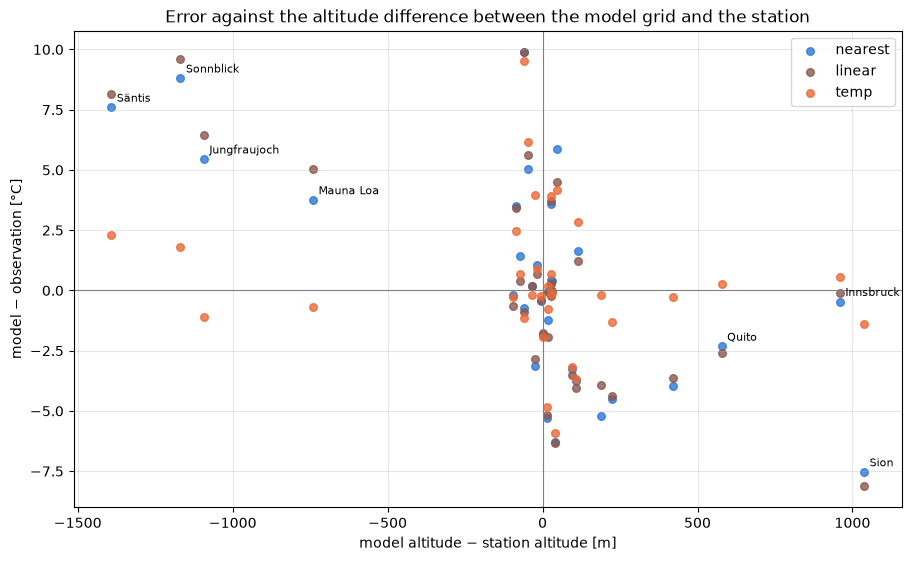

In [7]:
COLORS = {"nearest": "#2a78d6", "linear": "#8c564b", "temp": "#eb6834"}

alt_diff = pois["model altitude"] - pois["ELEVATION"]
fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
for label in METHODS:
    ax.scatter(alt_diff, diff[label], color=COLORS[label], s=30, label=label, alpha=0.8)
for name, x, y in zip(pois["name"], alt_diff, diff["nearest"]):
    if abs(x) > 500:
        ax.annotate(name, (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.axhline(0, color="0.5", lw=0.8)
ax.axvline(0, color="0.5", lw=0.8)
ax.set_xlabel("model altitude − station altitude [m]")
ax.set_ylabel("model − observation [°C]")
ax.set_title("Error against the altitude difference between the model grid and the station")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Performance benchmark

The first call includes building the neighbor search structures, which `grid_process` caches.
Subsequent calls on the same grid and stations (e.g. for other variables or runs) reuse them: their
runtime is the mean ± standard deviation over 5 repetitions.

In [8]:
def benchmark(
    func: Callable[..., xr.Dataset],
    data: xr.Dataset,
    target: gpd.GeoDataFrame | xr.Dataset,
    methods: dict[str, dict[str, Any]],
    first_call_times: dict[str, float],
    repeat: int = 5,
) -> pd.DataFrame:
    """Runtime of the first call and mean ± standard deviation of the subsequent calls of each method."""
    rows: dict[str, dict[str, Any]] = {}
    for method, kw in methods.items():
        times = np.array(timeit.repeat(partial(func, data, target, **kw), number=1, repeat=repeat))
        rows[method] = {
            "first call [s]": f"{first_call_times[method]:.3f}",
            "subsequent calls [s]": f"{times.mean():.3f} ± {times.std():.3f}",
        }
    return pd.DataFrame.from_dict(rows, orient="index").rename_axis("method")


print(f"{ds.latitude.size} × {ds.longitude.size} grid points -> {len(pois)} stations")
benchmark(gri.interp2poi, ds, pois, METHODS, first_call)

721 × 1440 grid points -> 33 stations


,first call [s],subsequent calls [s]
method,,
nearest,0.623,0.167 ± 0.003
linear,0.017,0.005 ± 0.000
temp,0.628,0.213 ± 0.003


## Takeaways

- At 0.25° the model orography smooths out the mountains: on Säntis, Sonnblick, Jungfraujoch and Mauna Loa
  the nearest grid point is 700 to 1400 m below the station, and `nearest` and `linear` are about 4 to 10 °C
  too warm. In the valley of Sion the grid point is 1000 m above the station, and they are about 8 °C too cold.
  `temp` corrects most of these differences: its errors stay within about 2.5 °C at these stations.
- Where the model altitude is close to the station altitude, the three methods agree. The remaining
  differences to the observations (e.g. in Mexico City, Manaus, Christchurch or at the South Pole) come from
  the model itself, not from the interpolation. Observations taken up to an hour from the valid time also
  add some differences.
- Coastal stations are more mixed: the neighborhood of `temp` contains land and sea grid points. At Nadi it
  removes most of the error of `nearest`, while at Dakar it is warmer than the observation.
- The ECEF neighbor search handles the stations next to the antimeridian (Nadi, Fua'amotu, Pago Pago) and
  close to the poles like any other. At the South Pole, all neighbors are the same pole point repeated in the
  first grid row: `temp` cannot fit a sounding and falls back to a fixed lapse rate.
- `linear` is not available in ECEF: on a regular latitude/longitude grid such as GFS it goes through the
  regular grid interpolation (`try_reg=True`, the default), which also handles the 0..360° longitudes of GFS
  and the stations across its 360° seam.
- The first call of `nearest` and `temp` includes converting the 1 million grid points to ECEF and building
  the neighbor search, about 0.6 s. Subsequent calls take about 0.2 s, and `linear` a few milliseconds.